<a href="https://colab.research.google.com/github/georgina-dev/sci-computing-cat-exercises/blob/main/question2_b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install scikit-learn

In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [9]:
data = {
    'Age': [12, 34, 56, 43, 98],
    'WaitingMinutes': [17, 28, 39, 42, 59],
    'VisitsPerYear': [3, 7, 6, 9, 12]
}

In [10]:
patients = pd.DataFrame(data)

In [11]:
# select numerical variables
X = patients[['Age', 'WaitingMinutes', 'VisitsPerYear']]

In [12]:
# handle missing values
X = X.dropna()

In [13]:
# standardise the variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
# perform PCA
pca = PCA()
principal_components = pca.fit_transform(X_scaled)

In [15]:
# explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance ratio:
[0.94881348 0.04318417 0.00800234]


In [17]:
# cumulative explained variance
print("Cumulative explained variance:")
print(pca.explained_variance_ratio_.cumsum())

Cumulative explained variance:
[0.94881348 0.99199766 1.        ]


In [18]:
# component loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2', 'PC3']
)

print("Principal component loadings:")
print(loadings)

Principal component loadings:
                     PC1       PC2       PC3
Age             0.575165 -0.633006 -0.518160
WaitingMinutes  0.587580 -0.121019  0.800065
VisitsPerYear   0.569153  0.764629 -0.302336


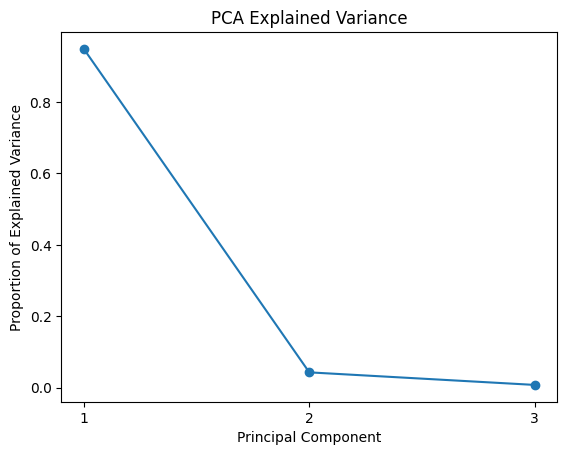

In [19]:
# plot explained variance
plt.plot(
    range(1, 4),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Proportion of Explained Variance")
plt.title("PCA Explained Variance")
plt.xticks([1, 2, 3])
plt.show()